# Flash drought decomposition reanalysis results

In [1]:
import glob as glob
import xarray as xr
import pandas as pd
import geopandas as gpd
import sys
import os
import numpy as np
import time
import zarr
import matplotlib.pyplot as plt
import gc

In [2]:
sys.path.append('/g/data/mn51/users/jb6465/code/flash-drought/attribution-python')
from attribution import *
from plotting import *
from extract import *

In [3]:
import warnings
import logging
warnings.filterwarnings('ignore') 
logging.getLogger("distributed.worker.memory").setLevel(logging.ERROR)
logging.getLogger("distributed.shuffle._scheduler_plugin").setLevel(logging.ERROR)
logging.getLogger('flox').setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [4]:
import dask
import tempfile
from dask.diagnostics import ProgressBar
from dask.distributed import Client, LocalCluster

dask.config.set({
    # 'array.chunk-size': "256 MiB",
    # 'array.slicing.split_large_chunks': True, #This can make AXIOM very slow
    'distributed.comm.timeouts.connect': '120s',
    'distributed.comm.timeouts.tcp': '120s',
    'distributed.comm.retry.count': 10,
    'distributed.scheduler.allowed-failures': 20,
    "distributed.scheduler.worker-saturation": 1.1, #This should use the new behaviour which helps with memory pile up
})

client = Client(n_workers=10, threads_per_worker=1, local_directory = tempfile.mkdtemp(), memory_limit = "765000mb")
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 10
Total threads: 10,Total memory: 6.96 TiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33453,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:44561,Total threads: 1
Dashboard: /proxy/41661/status,Memory: 712.46 GiB
Nanny: tcp://127.0.0.1:41531,


## Compute $ET_0$ (reanalysis)

In [5]:
short_tall_switch = 'short'

### BARRA-R2

In [ ]:
%%time
for year in range(1979, 2025): 
    if not os.path.isfile(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_BARRAR2_{year}.nc"):
        #mask ocean amd ingest ET0 inputs
        Rs = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/rsds/barra_domain_BARRAR2_{year}_rsds_day.nc').rsds)
        T = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tas/barra_domain_BARRAR2_{year}_tas_day.nc').tas)
        Tmax = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tasmax/barra_domain_BARRAR2_{year}_tasmax_day.nc').tasmax)
        Tmin = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tasmin/barra_domain_BARRAR2_{year}_tasmin_day.nc').tasmin)
        Patm = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/ps/barra_domain_BARRAR2_{year}_ps_day.nc').ps)
        Q2M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/huss/barra_domain_BARRAR2_{year}_huss_day.nc').huss)
        W10M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/sfcWind/barra_domain_BARRAR2_{year}_sfcWind_day.nc').sfcWind)
        elev =mask_ocean(xr.open_dataset(f'/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/v20231001/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc').orog)
    
        #compute daily ET0 for full period
        ET = compute_ref_ET(Rs*86400, T-273.15, Tmax-273.15, Tmin-273.15, None, Patm, W10M, Q2M, None, None, None, elev,
                          derive_2m_windspeed=True, short_tall_crop_switch=short_tall_switch, T2M_model_or_derived='derived', Patm_model_or_derived='model', esat_method='TmaxTmin', eact_method='Patm_q', Rnl_method='TmaxTmin')
    
        #save locally
        os.makedirs(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/", exist_ok=True)
        xr.Dataset({f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": ET}).reset_coords(drop=True).to_netcdf(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_BARRAR2_{year}.nc", encoding={f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": {"zlib": True, "complevel": 5, "dtype": "float32"}})

### BARRA-R2 w BARRA-C2 winds

In [ ]:
%%time
for year in range(1979, 2025): 
    if not os.path.isfile(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-C2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_BARRAR2_w_BARRAC2_winds_{year}.nc"):
        #mask ocean amd ingest ET0 inputs
        W10M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-C2/sfcWind/barra_domain_BARRAC2_{year}_sfcWind_day.nc').sfcWind)
        
        Rs = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/rsds/barra_domain_BARRAR2_{year}_rsds_day.nc').rsds)
        T = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tas/barra_domain_BARRAR2_{year}_tas_day.nc').tas)
        Tmax = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tasmax/barra_domain_BARRAR2_{year}_tasmax_day.nc').tasmax)
        Tmin = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/tasmin/barra_domain_BARRAR2_{year}_tasmin_day.nc').tasmin)
        Patm = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/ps/barra_domain_BARRAR2_{year}_ps_day.nc').ps)
        Q2M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/huss/barra_domain_BARRAR2_{year}_huss_day.nc').huss)
        elev =mask_ocean(xr.open_dataset(f'/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/v20231001/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc').orog)
    
        #compute daily ET0 for full period
        ET = compute_ref_ET(Rs*86400, T-273.15, Tmax-273.15, Tmin-273.15, None, Patm, W10M, Q2M, None, None, None, elev,
                          derive_2m_windspeed=True, short_tall_crop_switch=short_tall_switch, T2M_model_or_derived='derived', Patm_model_or_derived='model', esat_method='TmaxTmin', eact_method='Patm_q', Rnl_method='TmaxTmin')
    
        #save locally
        os.makedirs(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-C2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/", exist_ok=True)
        xr.Dataset({f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": ET}).reset_coords(drop=True).to_netcdf(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-C2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_BARRAR2_w_BARRAC2_winds_{year}.nc", encoding={f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": {"zlib": True, "complevel": 5, "dtype": "float32"}})

### MERRA2

In [ ]:
%%time
for year in range(1980, 2023): 
    if not os.path.isfile(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_MERRA2_{year}.nc"):
        #mask ocean amd ingest ET0 inputs
        Rs = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/SWGDN/barra_domain_MERRA2_{year}_SWGDN_day.nc').SWGDN)
        T = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_T2MDEW_QV2M_PS/barra_domain_MERRA2_{year}_T2M_T2MDEW_QV2M_PS_day.nc').T2M)
        Tdew = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_T2MDEW_QV2M_PS/barra_domain_MERRA2_{year}_T2M_T2MDEW_QV2M_PS_day.nc').T2MDEW)
        Tmax = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_MAX/barra_domain_MERRA2_{year}_T2M_MAX_day.nc').T2M)
        Tmin = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_MIN/barra_domain_MERRA2_{year}_T2M_MIN_day.nc').T2M)
        Patm = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_T2MDEW_QV2M_PS/barra_domain_MERRA2_{year}_T2M_T2MDEW_QV2M_PS_day.nc').PS)
        W2M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/W2M/barra_domain_MERRA2_{year}_W2M_day.nc').W2M)
        Q2M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/T2M_T2MDEW_QV2M_PS/barra_domain_MERRA2_{year}_T2M_T2MDEW_QV2M_PS_day.nc').QV2M)
        
        elevfile = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/archived/MERRA2_101.const_2d_asm_Nx.nc4')
        geopot = elevfile['PHIS'].sel(lat=slice(domain_dict['barra_domain']['lat_min'], domain_dict['barra_domain']['lat_max']), lon=slice(domain_dict['barra_domain']['lon_min'], domain_dict['barra_domain']['lon_max']))
        elev = geopot[0]/9.81 #divide by 9.81m2/s to get elevation [m]
        
        #compute daily ET0 for full period
        ET = compute_ref_ET(Rs*86400, T-273.15, Tmax-273.15, Tmin-273.15, Tdew-273.15, Patm, W2M, Q2M, None, None, None, elev,
                            derive_2m_windspeed=False, short_tall_crop_switch=short_tall_switch, T2M_model_or_derived='derived', Patm_model_or_derived='model', esat_method='TmaxTmin', eact_method='Patm_q', Rnl_method='TmaxTmin')
    
        #save locally
        os.makedirs(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/", exist_ok=True)
        xr.Dataset({f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": ET}).reset_coords(drop=True).to_netcdf(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_MERRA2_{year}.nc", encoding={f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": {"zlib": True, "complevel": 5, "dtype": "float32"}})

### ERA5 / ERA5-Land

In [51]:
%%time
ERA5_ERA5_Land_switch = 'ERA5-Land'
for year in range(1979, 2025):  
    if not os.path.isfile(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_{ERA5_ERA5_Land_switch}_{year}.nc"):
        #mask ocean amd ingest ET0 inputs
        Rs = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/ssrd/barra_domain_{ERA5_ERA5_Land_switch}_{year}_ssrd_day.nc').ssrd)
        T = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/2t/barra_domain_{ERA5_ERA5_Land_switch}_{year}_2t_day.nc').t2m)
        Tdew = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/2d/barra_domain_{ERA5_ERA5_Land_switch}_{year}_2d_day.nc').d2m)
        Tmax = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/2tMax/barra_domain_{ERA5_ERA5_Land_switch}_{year}_2tMax_day.nc').t2m)
        Tmin = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/2tMin/barra_domain_{ERA5_ERA5_Land_switch}_{year}_2tMin_day.nc').t2m)
        Patm = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/sp/barra_domain_{ERA5_ERA5_Land_switch}_{year}_sp_day.nc').sp)
        W10M = mask_ocean(xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/10w/barra_domain_{ERA5_ERA5_Land_switch}_{year}_10w_day.nc').w10)
        Q2M = 0.622 * (6.112*100*np.exp(17.67*(Tdew-273.15)/((Tdew-273.15)+243.5))) / (Patm - 0.378*(6.112*100*np.exp(17.67*(Tdew-273.15)/((Tdew-273.15)+243.5))))
        elev = mask_ocean(xr.open_dataset(f'/g/data/ob53/BARRA2/output/reanalysis/AUS-11/BOM/ERA5/historical/hres/BARRA-R2/v1/fx/orog/v20231001/orog_AUS-11_ERA5_historical_hres_BOM_BARRA-R2_v1.nc').orog).interp_like(Rs[0])
        
        #compute daily ET0 for full period
        ET = compute_ref_ET(Rs, T-273.15, Tmax-273.15, Tmin-273.15, Tdew-273.15, Patm, W10M, Q2M, None, None, None, elev,
                            derive_2m_windspeed=True, short_tall_crop_switch=short_tall_switch, T2M_model_or_derived='derived', Patm_model_or_derived='model', esat_method='TmaxTmin', eact_method='Patm_q', Rnl_method='TmaxTmin')
    
        #save locally
        os.makedirs(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/", exist_ok=True)
        xr.Dataset({f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": ET}).reset_coords(drop=True).to_netcdf(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/{ERA5_ERA5_Land_switch}/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_{ERA5_ERA5_Land_switch}_{year}.nc", encoding={f"{'ETr_tall_crop' if short_tall_switch == 'tall' else 'ET0_short_crop'}": {"zlib": True, "complevel": 5, "dtype": "float32"}})

CPU times: user 1h 8min 8s, sys: 21min 51s, total: 1h 29min 59s
Wall time: 1h 19min 27s


## $ET_0$ mean and variability climatology

In [52]:
warnings.filterwarnings("ignore", message="invalid value encountered in divide", category=RuntimeWarning)

In [54]:
BARRA_ref_ET = xr.open_mfdataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/*.nc").chunk({'time':-1, 'lat':'auto', 'lon':'auto'})[f"{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_crop"].sortby('time').sel(time=slice('1980', '2022'))
BARRA_ref_ET_mean = ((BARRA_ref_ET.assign_coords(doy=BARRA_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
BARRA_ref_ETr_var = ((BARRA_ref_ET.assign_coords(doy=BARRA_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

BARRAC_ref_ET = xr.open_mfdataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-C2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/*.nc").chunk({'time':-1, 'lat':'auto', 'lon':'auto'})[f"{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_crop"].sortby('time').sel(time=slice('1980', '2022'))
BARRAC_ref_ET_mean = ((BARRAC_ref_ET.assign_coords(doy=BARRAC_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
BARRAC_ref_ETr_var = ((BARRAC_ref_ET.assign_coords(doy=BARRAC_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

ERA5Land_ref_ET = xr.open_mfdataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/ERA5-Land/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/*.nc").chunk({'time':-1, 'lat':'auto', 'lon':'auto'})[f"{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_crop"].sortby('time').sel(time=slice('1980', '2022'))
ERA5Land_ref_ET_mean = ((ERA5Land_ref_ET.assign_coords(doy=ERA5Land_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
ERA5Land_ref_ET_var = ((ERA5Land_ref_ET.assign_coords(doy=ERA5Land_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

ERA5_ref_ET = xr.open_mfdataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/ERA5/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/*.nc").chunk({'time':-1, 'lat':'auto', 'lon':'auto'})[f"{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_crop"].sortby('time').sel(time=slice('1980', '2022'))
ERA5_ref_ET_mean = ((ERA5_ref_ET.assign_coords(doy=ERA5_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
ERA5_ref_ET_var = ((ERA5_ref_ET.assign_coords(doy=ERA5_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

MERRA2_ref_ET = xr.open_mfdataset(f"/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/MERRA2/RefET/{'ETr' if short_tall_switch == 'tall' else 'ET0'}/*.nc").chunk({'time':-1, 'lat':'auto', 'lon':'auto'})[f"{'ETr_tall' if short_tall_switch == 'tall' else 'ET0_short'}_crop"].sortby('time').sel(time=slice('1980', '2022'))
MERRA2_ref_ET_mean = ((MERRA2_ref_ET.assign_coords(doy=MERRA2_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
MERRA2_ref_ET_var = ((MERRA2_ref_ET.assign_coords(doy=MERRA2_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

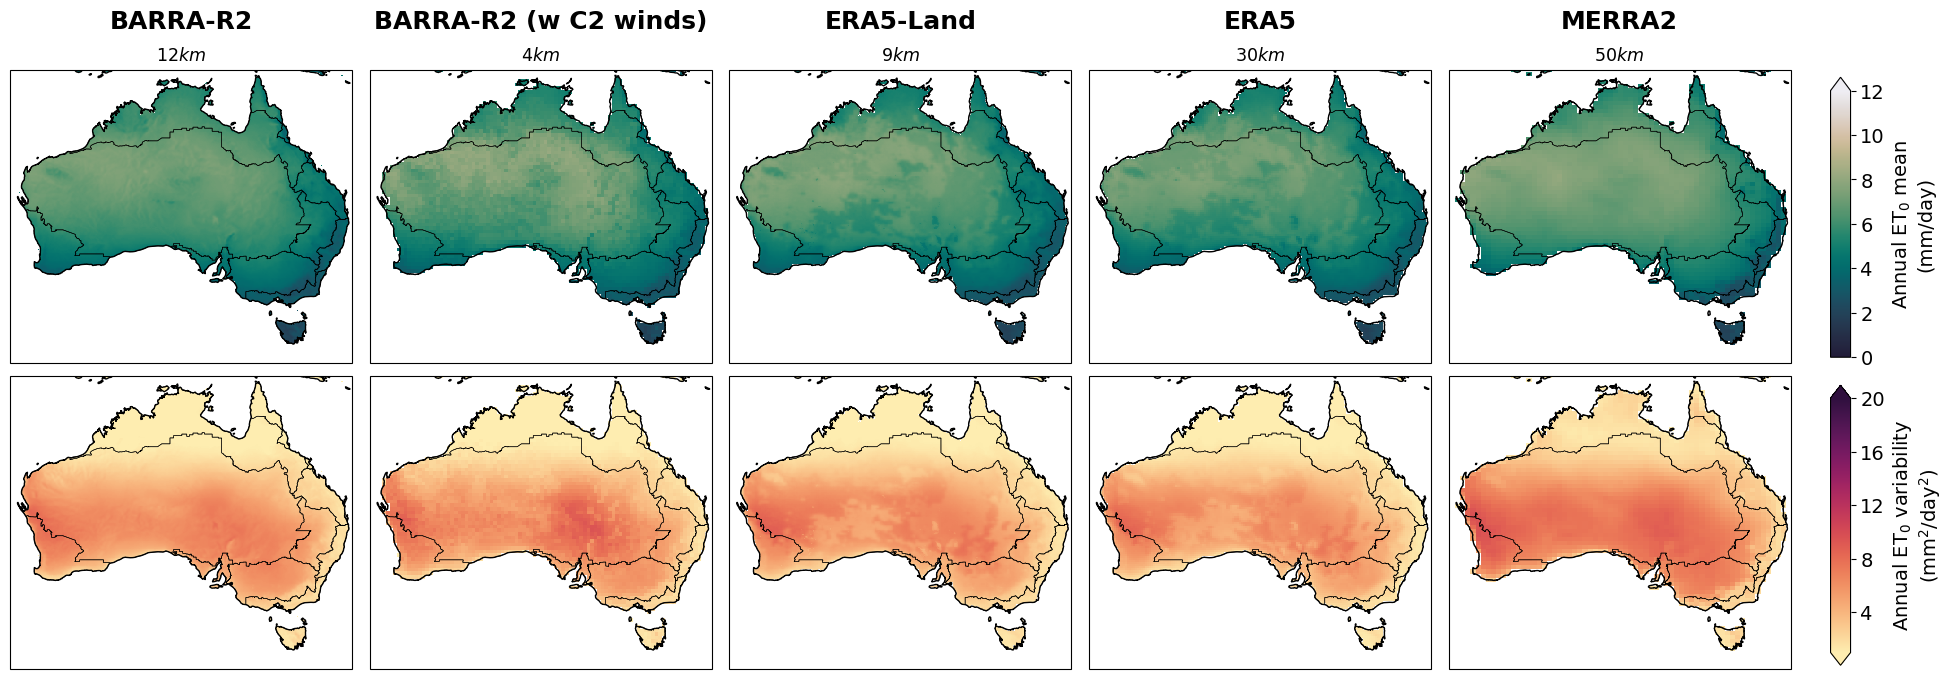

In [64]:
import cmocean
plot_extent = [112, 154, -44, -10] #[90, 180, -40, 9]
create_multiplot(nrows=2, ncols=5, plot_fontsize=14, title_size=18, figsize=(20, 7), plot_extent= plot_extent, plot_marker=None,
    plot_list=[[BARRA_ref_ET_mean, BARRAC_ref_ET_mean, ERA5Land_ref_ET_mean, ERA5_ref_ET_mean, MERRA2_ref_ET_mean],\
               [BARRA_ref_ETr_var, BARRAC_ref_ETr_var, ERA5Land_ref_ET_var, ERA5_ref_ET_var, MERRA2_ref_ET_var]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['BARRA-R2\n'+r'$_{12km}$', 'BARRA-R2 (w C2 winds)\n'+r'$_{4km}$', 'ERA5-Land\n'+r'$_{9km}$', 'ERA5\n'+r'$_{30km}$', 'MERRA2\n'+r'$_{50km}$'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.rain_r, cmocean.cm.matter],
    cbar_labels=['Annual ET$_r$ mean\n(mm/day)' if short_tall_switch == 'tall' else 'Annual ET$_0$ mean\n(mm/day)', \
                 'Annual ET$_r$ variability\n(mm$^2$/day$^2$)' if short_tall_switch == 'tall' else 'Annual ET$_0$ variability\n(mm$^2$/day$^2$)'],
    cbar_extensions=['max','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[7,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.04, 0.44),
    cbar_mins=[0,1],
    cbar_maxs=[12,20])

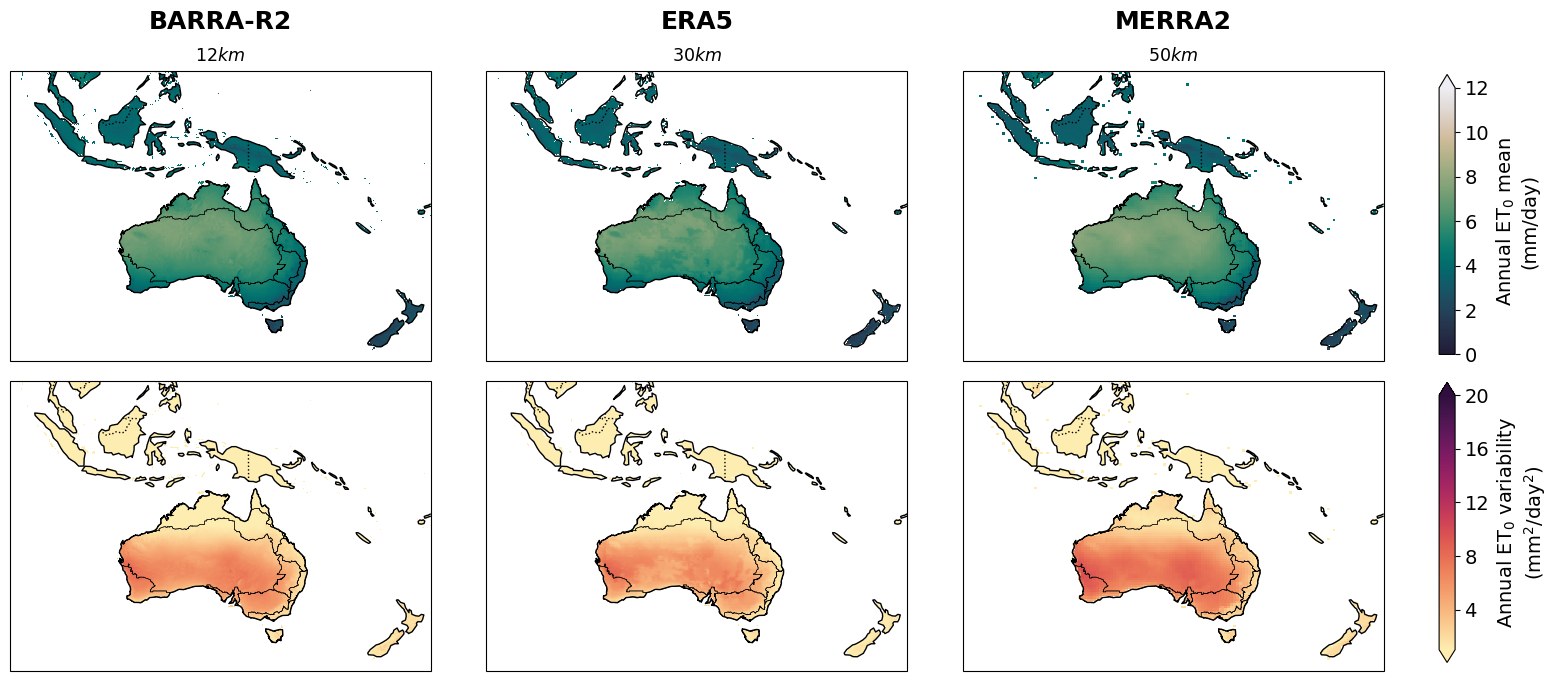

In [14]:
import cmocean

create_multiplot(nrows=2, ncols=5, plot_fontsize=14, title_size=18, figsize=(25, 7), plot_extent=[90, 180, -40, 9], plot_marker=None,
    plot_list=[[BARRA_ref_ET_mean, BARRAC_ref_ET_mean, ERA5Land_ref_ET_mean, ERA5_ref_ET_mean, MERRA2_ref_ET_mean],\
               [BARRA_ref_ETr_var, BARRAC_ref_ETr_var, ERA5Land_ref_ET_var, ERA5_ref_ET_var, MERRA2_ref_ET_var]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['BARRA-R2\n'+r'$_{12km}$', 'BARRA-R2 (BARRA-C2 winds)\n'+r'$_{4km}$', 'ERA5-Land\n'+r'$_{9km}$', 'ERA5\n'+r'$_{30km}$', 'MERRA2\n'+r'$_{50km}$'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.rain_r, cmocean.cm.matter],
    cbar_labels=['Annual ET$_r$ mean\n(mm/day)' if short_tall_switch == 'tall' else 'Annual ET$_0$ mean\n(mm/day)', \
                 'Annual ET$_r$ variability\n(mm$^2$/day$^2$)' if short_tall_switch == 'tall' else 'Annual ET$_0$ variability\n(mm$^2$/day$^2$)'],
    cbar_extensions=['max','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[7,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.04, 0.44),
    cbar_mins=[0,1],
    cbar_maxs=[12,20])

In [60]:
%%time
AWRA_ref_ET = xr.open_mfdataset(f"/g/data/iu04/australian-water-outlook/historical/v1/ET/{'asce' if short_tall_switch == 'tall' else 'fao'}*.nc").chunk({'time':-1, 'latitude':'auto', 'longitude':'auto'})[f"{'asce' if short_tall_switch == 'tall' else 'fao'}_pet"].sortby('time').sel(time=slice('1980', '2022')) 
AWRA_ref_ET_mean = ((AWRA_ref_ET.assign_coords(doy=AWRA_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time').chunk({'doy':-1, 'latitude':'auto', 'longitude':'auto'})).mean(dim='doy')).compute()
AWRA_ref_ET_var = ((AWRA_ref_ET.assign_coords(doy=AWRA_ref_ET['time'].dt.dayofyear).groupby('doy').mean('time').chunk({'doy':-1, 'latitude':'auto', 'longitude':'auto'})).var(dim='doy')).compute()


In [58]:
AWRA_ref_ET_mean = AWRA_ref_ET_mean.rename({'latitude': 'lat'}).rename({'longitude': 'lon'})
AWRA_ref_ET_var = AWRA_ref_ET_var.rename({'latitude': 'lat'}).rename({'longitude': 'lon'})

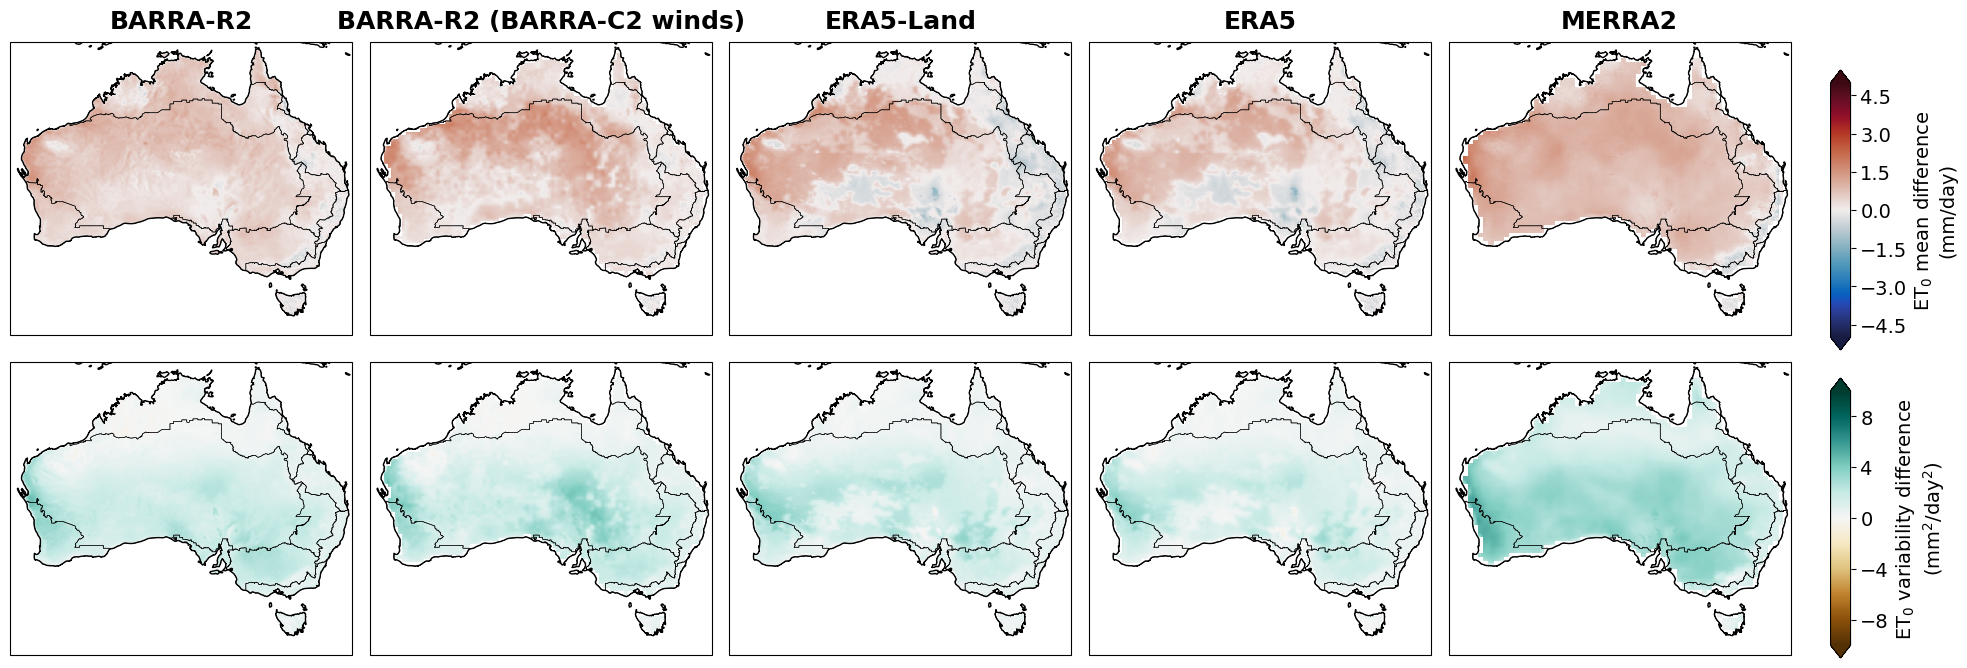

In [67]:
import cmocean
plot_extent = [112, 154, -44, -10] #[90, 180, -40, 9]
create_multiplot(nrows=2, ncols=5, plot_fontsize=14, title_size=18, figsize=(20, 7), plot_extent=plot_extent, plot_marker=None,
    plot_list=[[BARRA_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, BARRAC_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, ERA5Land_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, ERA5_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, MERRA2_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean],\
               [BARRA_ref_ETr_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, BARRAC_ref_ETr_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, ERA5Land_ref_ET_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, ERA5_ref_ET_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, MERRA2_ref_ET_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['BARRA-R2', 'BARRA-R2 (BARRA-C2 winds)', 'ERA5-Land', 'ERA5', 'MERRA2'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.balance, plt.cm.BrBG],
    cbar_labels=['ET$_r$ mean difference\n(mm/day)' if short_tall_switch == 'tall' else 'ET$_0$ mean difference\n(mm/day)',\
                 'ET$_r$ variability difference\n(mm$^2$/day$^2$)' if short_tall_switch == 'tall' else 'ET$_0$ variability difference\n(mm$^2$/day$^2$)'],
    cbar_extensions=['both','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[7,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.04, 0.44),
    cbar_mins=[-5,-10],
    cbar_maxs=[5,10])

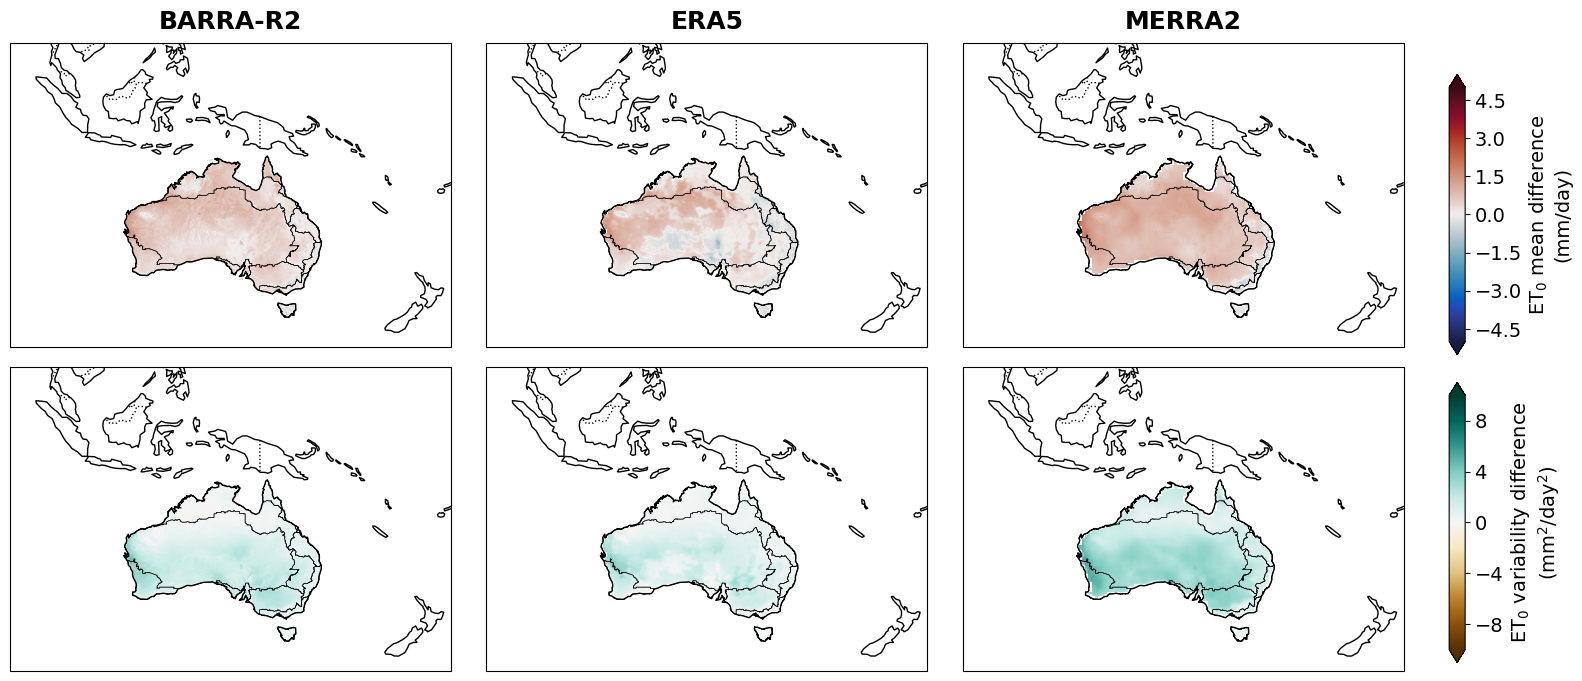

In [18]:
import cmocean

create_multiplot(nrows=2, ncols=3, plot_fontsize=14, title_size=18, figsize=(16, 7), plot_extent=[90, 180, -40, 9], plot_marker=None,
    plot_list=[[BARRA_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, ERA5_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean, MERRA2_ref_ET_mean.interp_like(AWRA_ref_ET_mean)-AWRA_ref_ET_mean],\
               [BARRA_ref_ETr_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, ERA5_ref_ET_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var, MERRA2_ref_ET_var.interp_like(AWRA_ref_ET_var)-AWRA_ref_ET_var]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['BARRA-R2', 'ERA5', 'MERRA2'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.balance, plt.cm.BrBG],
    cbar_labels=['ET$_r$ mean difference\n(mm/day)' if short_tall_switch == 'tall' else 'ET$_0$ mean difference\n(mm/day)',\
                 'ET$_r$ variability difference\n(mm$^2$/day$^2$)' if short_tall_switch == 'tall' else 'ET$_0$ variability difference\n(mm$^2$/day$^2$)'],
    cbar_extensions=['both','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[7,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.04, 0.44),
    cbar_mins=[-5,-10],
    cbar_maxs=[5,10])

In [ ]:
%%time
seasonal_dict_mean = {}
seasonal_dict_var = {}
keys = ['BARRA-R2', 'BARRA-C2', 'ERA5-Land', 'ERA5', 'MERRA2', 'AWRA']

for key_idx, mean_xr in enumerate([BARRA_ref_ET, BARRAC_ref_ET, ERA5Land_ref_ET, ERA5_ref_ET, MERRA2_ref_ET, AWRA_ref_ET]):
    seasonal_dict_mean[keys[key_idx]] = mean_xr.resample(time="QS-DEC").mean().groupby("time.season").mean("time", skipna=True).compute()
    seasonal_dict_var[keys[key_idx]] = mean_xr.resample(time="QS-DEC").mean().groupby("time.season").var("time", skipna=True).compute()